In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import joblib

# Preprocessing
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# KNN
from sklearn.neighbors import KNeighborsClassifier

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report,
    RocCurveDisplay
)

RANDOM_STATE = 42

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
PROJECT_ROOT = Path.cwd().parent

DATA_DIR = PROJECT_ROOT / "data"
MODEL_DIR = PROJECT_ROOT / "models"
RESULTS_DIR = PROJECT_ROOT / "results"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

train_data = pd.read_csv(DATA_DIR / "train_data.csv")
test_data = pd.read_csv(DATA_DIR / "test_data.csv")

print("Training dataset:", train_data.shape)
print("Testing dataset:", test_data.shape)

display(train_data.head())

Training dataset: (5616, 20)
Testing dataset: (1405, 20)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Male,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,No,Credit card (automatic),70.70,140.70,Yes
1,Female,0,No,No,15,Yes,Yes,Fiber optic,Yes,No,Yes,No,No,No,Month-to-month,Yes,Credit card (automatic),84.35,1302.65,No
2,Male,0,Yes,Yes,67,Yes,Yes,Fiber optic,No,Yes,No,No,No,Yes,Month-to-month,Yes,Bank transfer (automatic),89.55,6373.10,No
3,Male,0,No,No,5,Yes,No,DSL,No,Yes,No,Yes,No,Yes,Month-to-month,Yes,Bank transfer (automatic),65.60,339.90,No
4,Male,0,No,No,26,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,Yes,Electronic check,20.30,511.25,No


In [3]:
TARGET_COLUMN = "Churn"

X_train = train_data.drop(columns=[TARGET_COLUMN])
y_train = train_data[TARGET_COLUMN].map({
    "No": 0,
    "Yes": 1
})

X_test = test_data.drop(columns=[TARGET_COLUMN])
y_test = test_data[TARGET_COLUMN].map({
    "No": 0,
    "Yes": 1
})

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (5616, 19)
y_train: (5616,)
X_test: (1405, 19)
y_test: (1405,)


In [4]:
numerical_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

categorical_features = [
    col for col in X_train.columns
    if col not in numerical_features
]

print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))

Numerical features: 3
Categorical features: 16


In [5]:
numerical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

In [6]:
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ))
    ]
)

In [7]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("KNN preprocessor created successfully!")

KNN preprocessor created successfully!


In [8]:
KNeighborsClassifier(
    n_neighbors=5,
    weights="uniform",
    algorithm="auto",
    metric="minkowski",
    p=2,
    n_jobs=-1
)

,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",-1
,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None


In [9]:
knn_classifier = KNeighborsClassifier(
    n_neighbors=5,
    weights="uniform",
    algorithm="auto",
    metric="minkowski",
    p=2,
    n_jobs=-1
)

print(knn_classifier)

KNeighborsClassifier(n_jobs=-1)


In [10]:
knn_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", knn_classifier)
    ]
)

print("KNN pipeline created successfully!")

KNN pipeline created successfully!


In [11]:
knn_pipeline.fit(X_train, y_train)

print("KNN training completed!")

KNN training completed!


In [12]:
trained_knn = knn_pipeline.named_steps["classifier"]

print("Number of neighbors:", trained_knn.n_neighbors)
print("Distance metric:", trained_knn.metric)
print("Distance parameter p:", trained_knn.p)

print(
    "Number of training observations stored:",
    trained_knn.n_samples_fit_
)

Number of neighbors: 5
Distance metric: minkowski
Distance parameter p: 2
Number of training observations stored: 5616


In [13]:
y_pred = knn_pipeline.predict(X_test)

y_pred_proba = knn_pipeline.predict_proba(X_test)[:, 1]

results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred,
    "Churn_Probability": y_pred_proba
})

display(results.head(10))

,Actual,Predicted,Churn_Probability
0,0,1,0.8
1,1,1,0.6
2,1,0,0.4
3,0,0,0.2
4,0,0,0.0
5,0,0,0.4
6,0,0,0.0
7,1,1,1.0
8,0,0,0.0
9,0,0,0.0


In [14]:
knn_metrics = {
    "Model": "KNN",

    "Accuracy": accuracy_score(y_test, y_pred),

    "AUC": roc_auc_score(y_test, y_pred_proba),

    "Precision": precision_score(
        y_test, y_pred, zero_division=0
    ),

    "Recall": recall_score(
        y_test, y_pred, zero_division=0
    ),

    "F1": f1_score(
        y_test, y_pred, zero_division=0
    ),

    "MCC": matthews_corrcoef(y_test, y_pred)
}

knn_metrics_df = pd.DataFrame([knn_metrics])

display(
    knn_metrics_df.style.format({
        "Accuracy": "{:.4f}",
        "AUC": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}",
        "MCC": "{:.4f}"
    })
)

,Model,Accuracy,AUC,Precision,Recall,F1,MCC
0,KNN,0.7594,0.7720,0.5512,0.4919,0.5199,0.3611


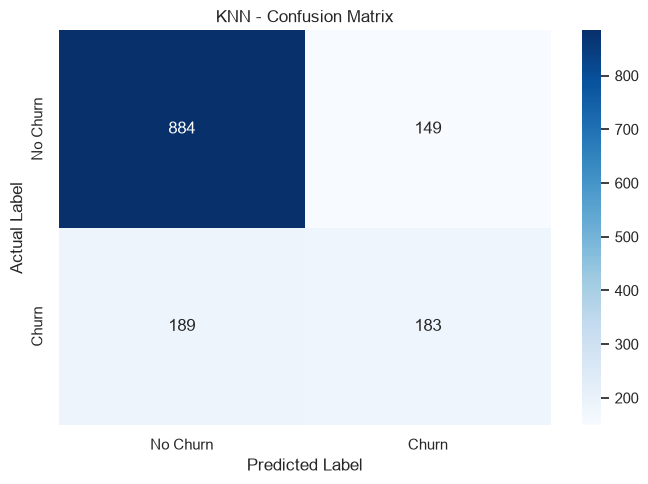

In [15]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.title("KNN - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()
plt.show()

In [16]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["No Churn", "Churn"],
        digits=4,
        zero_division=0
    )
)

              precision    recall  f1-score   support

    No Churn     0.8239    0.8558    0.8395      1033
       Churn     0.5512    0.4919    0.5199       372

    accuracy                         0.7594      1405
   macro avg     0.6875    0.6738    0.6797      1405
weighted avg     0.7517    0.7594    0.7549      1405



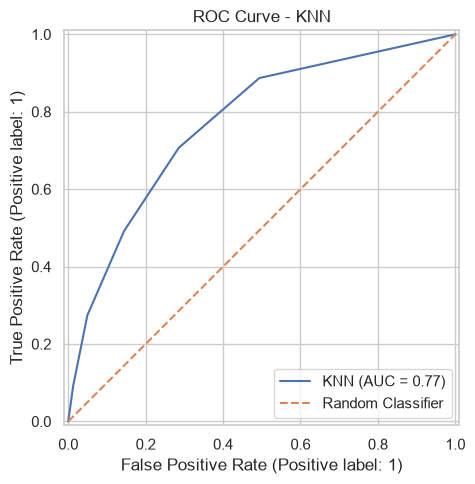

In [17]:
fig, ax = plt.subplots(figsize=(7, 5))

RocCurveDisplay.from_predictions(
    y_test,
    y_pred_proba,
    name="KNN",
    ax=ax
)

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

ax.set_title("ROC Curve - KNN")
ax.legend()

plt.tight_layout()
plt.show()

In [18]:
MODEL_PATH = MODEL_DIR / "knn.joblib"

joblib.dump(
    knn_pipeline,
    MODEL_PATH
)

print("KNN model saved successfully!")
print("Location:", MODEL_PATH)

KNN model saved successfully!
Location: /Users/walsri/Documents/masters/machine learning/assignments/assignment_2/telecom-customer-churn/models/knn.joblib


In [19]:
knn_metrics_df.to_csv(
    RESULTS_DIR / "knn_metrics.csv",
    index=False
)

print("KNN evaluation metrics exported successfully!")

KNN evaluation metrics exported successfully!


In [20]:
from sklearn.base import clone

k_values = range(1, 16)

k_results = []

# Fit preprocessing only on training data
X_train_transformed = (
    knn_pipeline.named_steps["preprocessor"].transform(X_train)
)

X_test_transformed = (
    knn_pipeline.named_steps["preprocessor"].transform(X_test)
)

for k in k_values:

    model = KNeighborsClassifier(
        n_neighbors=k,
        weights="uniform",
        metric="minkowski",
        p=2,
        n_jobs=-1
    )

    model.fit(X_train_transformed, y_train)

    predictions = model.predict(X_test_transformed)
    probabilities = model.predict_proba(X_test_transformed)[:, 1]

    k_results.append({
        "K": k,
        "Accuracy": accuracy_score(y_test, predictions),
        "AUC": roc_auc_score(y_test, probabilities),
        "F1": f1_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions)
    })

k_results_df = pd.DataFrame(k_results)

display(k_results_df.round(4))

,K,Accuracy,AUC,F1,Recall
0,1,0.7246,0.6415,0.4720,0.4651
1,2,0.7552,0.7034,0.3606,0.2608
2,3,0.7459,0.7402,0.4979,0.4758
3,4,0.7680,0.7626,0.4418,0.3468
4,5,0.7594,0.7720,0.5199,0.4919
5,6,0.7680,0.7828,0.4825,0.4086
6,7,0.7601,0.7905,0.5233,0.4973
7,8,0.7715,0.7966,0.5129,0.4543
8,9,0.7701,0.8006,0.5392,0.5081
9,10,0.7751,0.8078,0.5123,0.4462


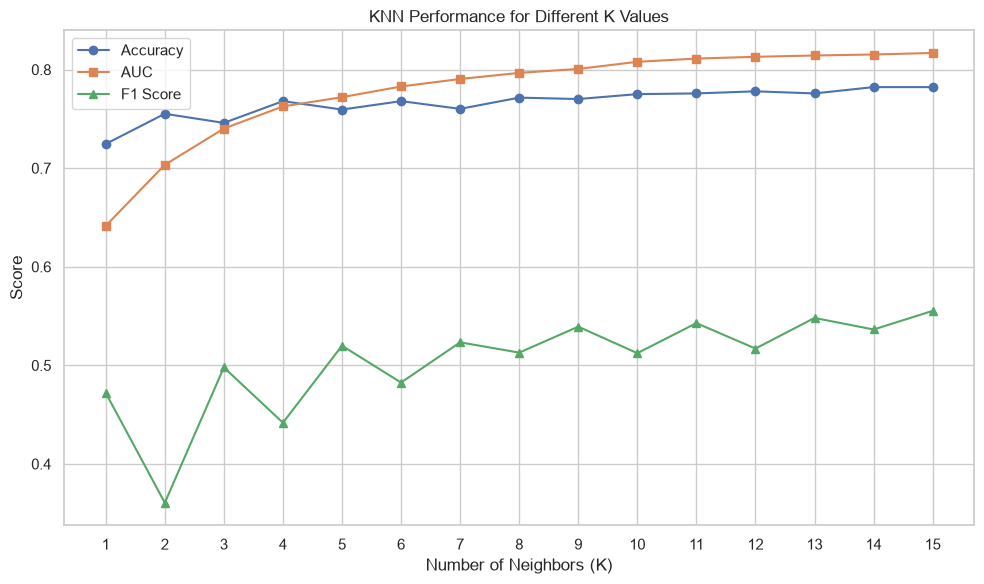

In [21]:
plt.figure(figsize=(10, 6))

plt.plot(
    k_results_df["K"],
    k_results_df["Accuracy"],
    marker="o",
    label="Accuracy"
)

plt.plot(
    k_results_df["K"],
    k_results_df["AUC"],
    marker="s",
    label="AUC"
)

plt.plot(
    k_results_df["K"],
    k_results_df["F1"],
    marker="^",
    label="F1 Score"
)

plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Score")
plt.title("KNN Performance for Different K Values")

plt.xticks(list(k_values))
plt.legend()
plt.tight_layout()
plt.show()